# Heart Disease UCI — data preparation and exploratory analysis

Dataset: **Heart Disease, UCI Machine Learning Repository** (dataset id 45), processed Cleveland file. UCI publishes 14 attributes: 13 patient features and `num`, a 0–4 disease grade that is turned into a binary target (0 = absent, 1 = present).

The data is obtained with `python scripts/download_data.py`, which downloads the raw file and writes the cleaned table to `data/processed/heart_clean.csv`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from heart.config import (
    BINARY_FEATURES,
    CATEGORICAL_FEATURES,
    FIGURES_DIR,
    NUMERIC_FEATURES,
    TARGET,
)
from heart.data import clean, load_raw, summarise
from heart.features import build_preprocessor

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {0: "#2a9d8f", 1: "#e76f51"}
LABELS = {0: "No disease", 1: "Disease"}

raw = load_raw()
df = clean(raw)
print(f"Raw file: {raw.shape[0]} rows x {raw.shape[1]} columns")
df.head()

Raw file: 303 rows x 14 columns


,age,trestbps,chol,thalach,oldpeak,ca,cp,restecg,slope,thal,sex,fbs,exang,target
0,63.0,145.0,233.0,150.0,2.3,0.0,1.0,2.0,3.0,6.0,1.0,1.0,0.0,0
1,67.0,160.0,286.0,108.0,1.5,3.0,4.0,2.0,2.0,3.0,1.0,0.0,1.0,1
2,67.0,120.0,229.0,129.0,2.6,2.0,4.0,2.0,2.0,7.0,1.0,0.0,1.0,1
3,37.0,130.0,250.0,187.0,3.5,0.0,3.0,0.0,3.0,3.0,1.0,0.0,0.0,0
4,41.0,130.0,204.0,172.0,1.4,0.0,2.0,2.0,1.0,3.0,0.0,0.0,0.0,0


## Data types and value ranges

In [2]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2
ca,299.0,0.67,0.94,0.0,0.0,0.0,1.0,3.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
slope,303.0,1.60,0.62,1.0,1.0,2.0,2.0,3.0
thal,301.0,4.73,1.94,3.0,3.0,3.0,7.0,7.0


## Missing values

The raw file marks unknown values with `?`. They are read as missing (NaN). They are **not** filled here: the model pipeline imputes them (median for numeric columns, most frequent value for categorical columns) using statistics from the training data only.

In [3]:
s = summarise(df)
missing = df.isna().sum()
missing = missing[missing > 0].rename("missing values").to_frame()
missing["% of rows"] = (missing["missing values"] / len(df) * 100).round(2)
display(missing)
print(
    f"{s['rows_with_missing']} of {s['rows']} rows have at least one missing value; "
    f"duplicate rows: {s['duplicate_rows']}."
)

,missing values,% of rows
ca,4,1.32
thal,2,0.66


6 of 303 rows have at least one missing value; duplicate rows: 0.


## Class balance

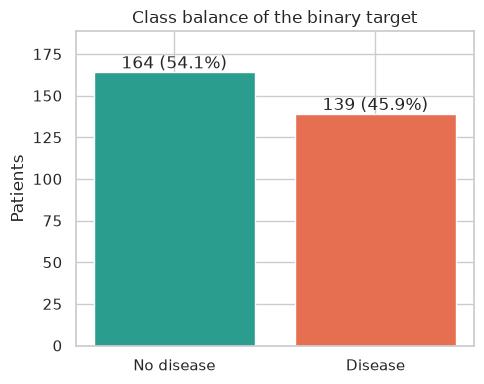

Minority/majority ratio: 0.85. The classes are close to balanced, so accuracy stays meaningful; stratified splits keep this ratio in every fold.


In [4]:
counts = df[TARGET].value_counts().sort_index()
share = counts / counts.sum() * 100
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(
    [LABELS[k] for k in counts.index], counts.values, color=[PALETTE[k] for k in counts.index]
)
for bar, n, p in zip(bars, counts.values, share.values, strict=True):
    ax.annotate(f"{n} ({p:.1f}%)", (bar.get_x() + bar.get_width() / 2, n), ha="center", va="bottom")
ax.set_title("Class balance of the binary target")
ax.set_ylabel("Patients")
ax.set_ylim(0, counts.max() * 1.15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "class_balance.png", dpi=150)
plt.show()
ratio = counts.min() / counts.max()
print(
    f"Minority/majority ratio: {ratio:.2f}. "
    + (
        "The classes are close to balanced, so accuracy stays meaningful; "
        "stratified splits keep this ratio in every fold."
        if ratio >= 0.7
        else "The classes are imbalanced; recall and ROC-AUC matter more than accuracy."
    )
)

## Distribution of the numeric features (histograms by class)

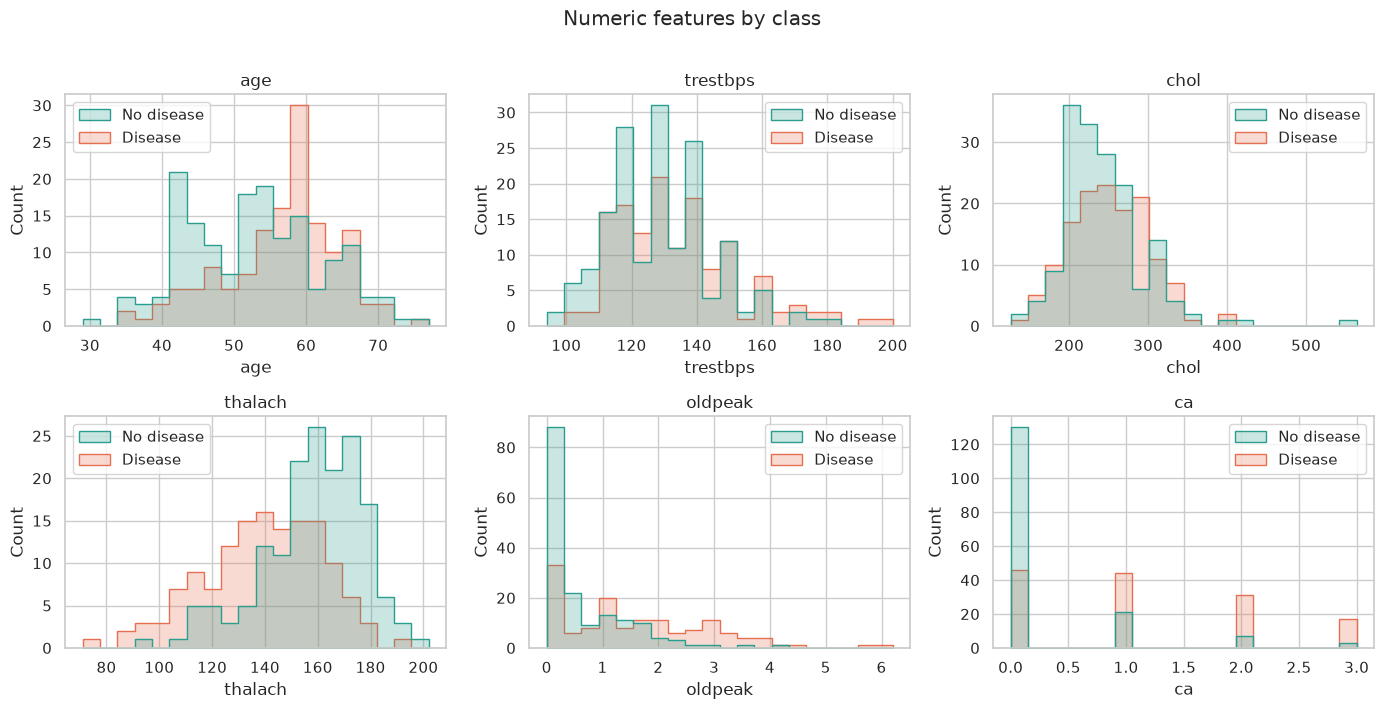

,No disease,Disease,difference
age,52.59,56.63,4.04
trestbps,129.25,134.57,5.32
chol,242.64,251.47,8.83
thalach,158.38,139.26,-19.12
oldpeak,0.59,1.57,0.99
ca,0.27,1.14,0.86


Largest class difference in standard-deviation units: ca (0.92), oldpeak (0.85), thalach (0.84).


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, NUMERIC_FEATURES, strict=True):
    sns.histplot(
        x=df[col],
        hue=df[TARGET].map(LABELS),
        bins=20,
        element="step",
        palette={LABELS[k]: v for k, v in PALETTE.items()},
        hue_order=[LABELS[0], LABELS[1]],
        ax=ax,
    )
    ax.set_title(col)
    ax.get_legend().set_title("")
fig.suptitle("Numeric features by class", y=1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "numeric_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

means = df.groupby(TARGET)[NUMERIC_FEATURES].mean().T
means.columns = [LABELS[c] for c in means.columns]
means["difference"] = means[LABELS[1]] - means[LABELS[0]]
display(means.round(2))
top = means["difference"].abs().div(df[NUMERIC_FEATURES].std()).sort_values(ascending=False)
print(
    "Largest class difference in standard-deviation units: "
    + ", ".join(f"{c} ({v:.2f})" for c, v in top.head(3).items())
    + "."
)

## Disease rate across categorical and binary features

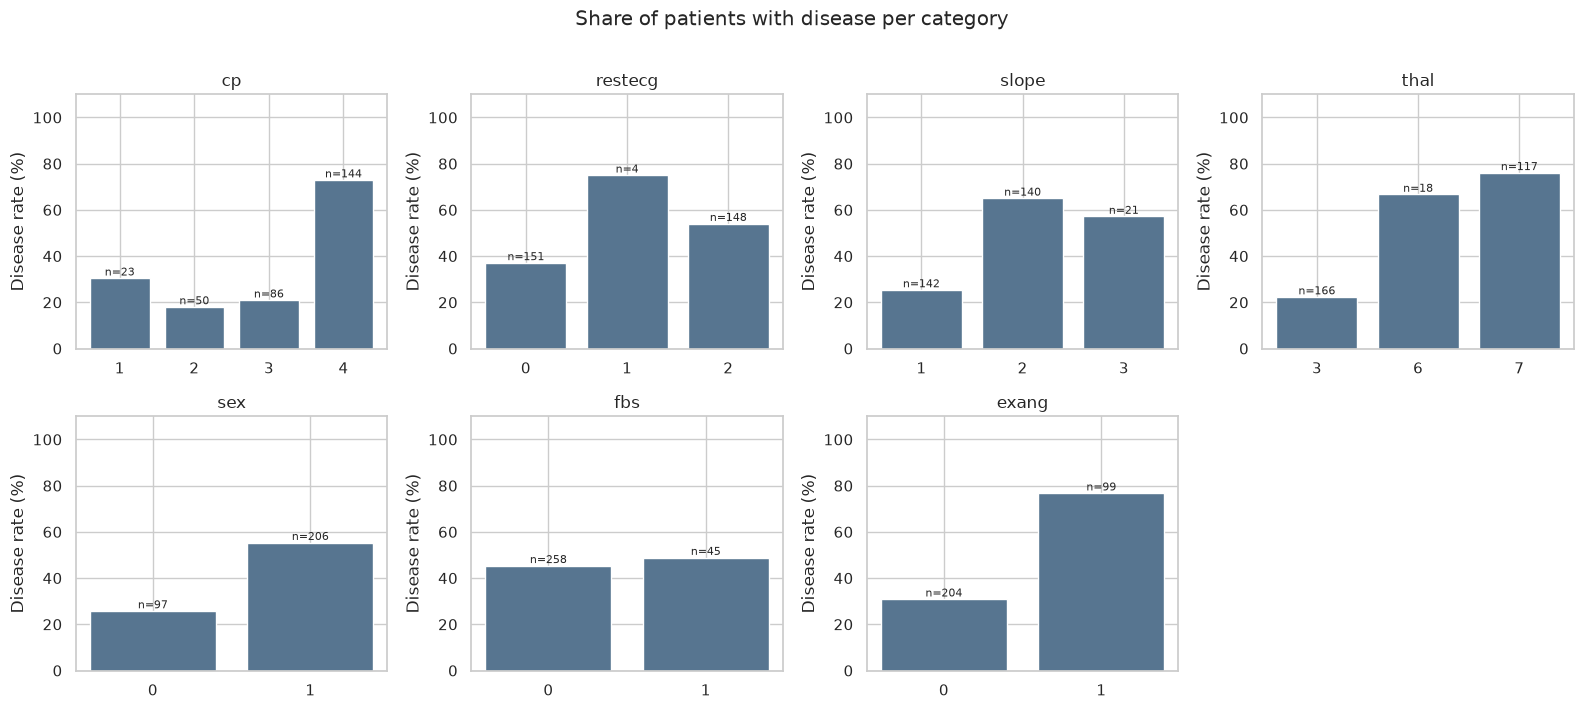

In [6]:
cats = CATEGORICAL_FEATURES + BINARY_FEATURES
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, cats, strict=False):
    rate = df.groupby(col)[TARGET].agg(["mean", "size"])
    ax.bar(rate.index.astype(int).astype(str), rate["mean"] * 100, color="#577590")
    for x, (m, n) in enumerate(zip(rate["mean"], rate["size"], strict=True)):
        ax.annotate(f"n={n}", (x, m * 100), ha="center", va="bottom", fontsize=8)
    ax.set_title(col)
    ax.set_ylabel("Disease rate (%)")
    ax.set_ylim(0, 110)
axes.flat[-1].axis("off")
fig.suptitle("Share of patients with disease per category", y=1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "categorical_disease_rate.png", dpi=150, bbox_inches="tight")
plt.show()

## Correlation heatmap

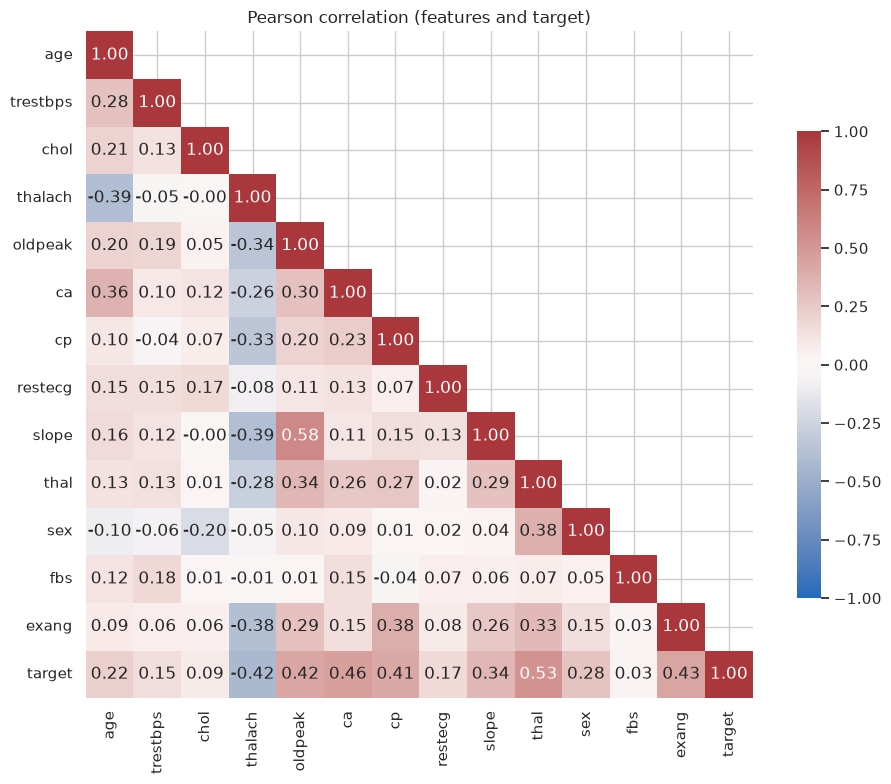

Strongest correlations with the target: thal (+0.53), ca (+0.46), exang (+0.43), oldpeak (+0.42).
Strongest correlation between two features: oldpeak-slope (+0.58); no pair is strong enough to make a feature redundant.


In [7]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"shrink": 0.7},
    ax=ax,
)
ax.set_title("Pearson correlation (features and target)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=150)
plt.show()

with_target = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print(
    "Strongest correlations with the target: "
    + ", ".join(f"{c} ({v:+.2f})" for c, v in with_target.head(4).items())
    + "."
)
pairs = (
    corr.drop(index=TARGET, columns=TARGET)
    .where(~np.tril(np.ones_like(corr.drop(index=TARGET, columns=TARGET), dtype=bool)))
    .stack()
)
a, b = pairs.abs().idxmax()
print(
    f"Strongest correlation between two features: {a}-{b} ({pairs[(a, b)]:+.2f}); "
    + (
        "no pair is strong enough to make a feature redundant."
        if abs(pairs[(a, b)]) < 0.7
        else "this pair is strongly collinear."
    )
)

## Disease rate by age band and sex

Age and sex are the two attributes a clinician knows before any test. This view shows how the base rate shifts across them.

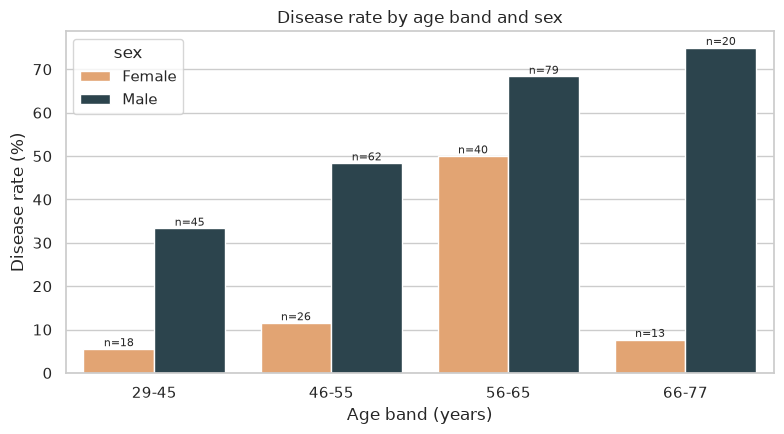

Disease rate: men 55.3%, women 25.8%. Women are 97 of 303 patients, so the female bars rest on small groups.


In [8]:
bands = pd.cut(df["age"], bins=[28, 45, 55, 65, 80], labels=["29-45", "46-55", "56-65", "66-77"])
table = (
    df.assign(age_band=bands, sex=df["sex"].map({0: "Female", 1: "Male"}))
    .groupby(["age_band", "sex"], observed=True)[TARGET]
    .agg(["mean", "size"])
    .reset_index()
)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=table,
    x="age_band",
    y=table["mean"] * 100,
    hue="sex",
    palette={"Female": "#f4a261", "Male": "#264653"},
    ax=ax,
)
for container, (_, grp) in zip(ax.containers, table.groupby("sex", observed=True), strict=True):
    ax.bar_label(container, labels=[f"n={n}" for n in grp["size"]], fontsize=8)
ax.set_xlabel("Age band (years)")
ax.set_ylabel("Disease rate (%)")
ax.set_title("Disease rate by age band and sex")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "disease_rate_age_sex.png", dpi=150)
plt.show()

by_sex = df.groupby("sex")[TARGET].mean() * 100
print(
    f"Disease rate: men {by_sex[1]:.1f}%, women {by_sex[0]:.1f}%. "
    f"Women are {int((df['sex'] == 0).sum())} of {len(df)} patients, so the female "
    "bars rest on small groups."
)

## Encoding plan

Encoding is part of the model pipeline (`src/heart/features.py`):

| Group | Columns | Steps |
|---|---|---|
| Numeric | age, trestbps, chol, thalach, oldpeak, ca | median imputation, standard scaling |
| Categorical | cp, restecg, slope, thal | most-frequent imputation, one-hot encoding |
| Binary | sex, fbs, exang | most-frequent imputation, kept as 0/1 |

`ca` (number of major vessels, 0–3) is ordered, so it stays numeric. `cp`, `restecg`, `slope` and `thal` are codes without a numeric order, so they are one-hot encoded.

In [9]:
pre = build_preprocessor().fit(df.drop(columns=TARGET))
encoded = pre.transform(df.drop(columns=TARGET))
names = pre.get_feature_names_out()
print(f"Before encoding: {df.shape[1] - 1} features; after encoding: {encoded.shape[1]} columns.")
print(
    "One-hot columns:",
    ", ".join(n for n in names if "_" in n and n.split("_")[0] in CATEGORICAL_FEATURES),
)

Before encoding: 13 features; after encoding: 22 columns.
One-hot columns: cp_1.0, cp_2.0, cp_3.0, cp_4.0, restecg_0.0, restecg_1.0, restecg_2.0, slope_1.0, slope_2.0, slope_3.0, thal_3.0, thal_6.0, thal_7.0
